In [198]:
#import des bibliothèques 
import pandas as pd
import numpy as np 
from scipy.spatial.transform import Rotation
from pathlib import Path

In [199]:
#import des données 
lat_col = "latitude"
lon_col="longitude"
time_col="timestamp"

In [200]:
#calcul de la distance entre deux points 
def haversine(lat1,lon1,lat2,lon2):
    R=6371000
    
    lat1=np.radians(lat1)
    lon1=np.radians(lon1)
    lat2=np.radians(lat2)
    lon2=np.radians(lon2)
    
    dlat=lat2-lat1
    dlon=lon2-lon1
    
    a = (np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2)
    
    return 2*R*np.arcsin(np.sqrt(a))


In [201]:
def remove_gnss_aberrant(df,lat_col="latitude",lon_col="longitude",seuil_grand=30,seuil_petit=10):
    """Supprime les points GNSS aberrants"""
    
    df=df.copy()
    #shift(1) point précédent 
    #shift(-1) point suivant
    
    df = df[(df[lat_col].between(-90, 90)) & (df[lon_col].between(-180, 180))]
    
    #Calcul de la distance entre le point préédent et le point courant
    df["d_prev"]=haversine(df[lat_col].shift(1),
                          df[lon_col].shift(1),
                          df[lat_col],
                          df[lon_col])
    
    #Calcul de la distance entre le point courant et le point suivant
    df["d_next"]=haversine(df[lat_col],
                          df[lon_col],
                          df[lat_col].shift(-1),
                          df[lon_col].shift(-1))
    
    #Calcul de la distance entre le point préédent et le point suivant
    df["d_skip"]=haversine(df[lat_col].shift(1),
                          df[lon_col].shift(1),
                          df[lat_col].shift(-1),
                          df[lon_col].shift(-1))
    
    #on ajoute une colonne pour savoir si le point courant est abberant ou non 
    df["est_aberrant"] = (
        (df["d_prev"] > seuil_grand)
        & (df["d_next"] > seuil_grand)
        & (df["d_skip"] < seuil_petit)
    )
    
    print("Nombre de points total :", len(df))
    print("Nombre de points aberrants détectés :", df["est_aberrant"].sum())
    
    return df[df["est_aberrant"]==False].copy()

In [202]:
R_EARTH=6371000
def latlon_to_xy(lat,lon,lat0,lon0):
    lat=np.asarray(lat)
    lon=np.asarray(lon)
    
    x=np.radians(lon-lon0)*R_EARTH*np.cos(np.radians(lat0))
    y=np.radians(lat-lat0)*R_EARTH
    return x,y

In [203]:
def xy_to_latlon(x,y,lat0,lon0):
    lat=lat0+np.degrees(y/R_EARTH)
    lon=lon0+np.degrees(x/(R_EARTH*np.cos(np.radians(lat0))))
    return lat,lon

In [204]:
def cap_magnetique(df):
    """Calcule lorientation horizontale à partir du magnétomètre du téléphone.

    Le téléphone mesure le champ magnétique terrestre selon deux axes :

        mx : composante horizontale Est/Ouest
        my : composante verticale Nord/Sud"""
    
    mx=df["mag_x"].to_numpy()
    my=df["mag_y"].to_numpy()
    
    cap=np.arctan2(my,mx)
    
    #supprime les auts trop grand d'angle
    cap=np.unwrap(cap)
    
    return cap

Anciennes estimations de R et Q mais qui donnait la même chose 

In [205]:
def estimer_R_gps(df_statique, lat_col="latitude", lon_col="longitude"):
    """Estimation de R avec une acquisition immobile """
    lat0 = df_statique[lat_col].mean()
    lon0 = df_statique[lon_col].mean()
    
    x, y = latlon_to_xy(df_statique[lat_col], df_statique[lon_col], lat0, lon0)
    
    var_x = np.var(x)
    var_y = np.var(y)
    
    print(f"σ_x = {np.sqrt(var_x):.3f} m,  σ_y = {np.sqrt(var_y):.3f} m")
    
    R_gps = np.diag([var_x, var_y])
    return R_gps

In [206]:
def estimer_R_mag(df_statique):
    cap = cap_magnetique(df_statique)
    var_cap = np.var(cap)
    print(f"σ_mag = {np.degrees(np.sqrt(var_cap)):.2f}°")
    return np.array([[var_cap]])

In [207]:
def estimer_Q(df_statique, dt_moyen):
    """
    Sur données statiques : le téléphone ne bouge pas,
    donc toute variance mesurée = bruit capteur pur.
    """
    var_ax = np.var(df_statique["accel_x"])
    var_ay = np.var(df_statique["accel_y"])
    var_gz = np.var(np.radians(df_statique["gyro_z"]))
    
    var_pos = 0.25 * max(var_ax, var_ay) * dt_moyen**4  
    var_vel = max(var_ax, var_ay) * dt_moyen**2         
    var_theta = var_gz * dt_moyen**2                      
    var_biais = (np.radians(0.02))**2                    

    print(f"σ_pos = {np.sqrt(var_pos):.4f} m")
    print(f"σ_vel = {np.sqrt(var_vel):.4f} m/s")
    print(f"σ_theta = {np.degrees(np.sqrt(var_theta)):.4f}°")

    Q = np.diag([
        var_pos, var_pos,
        var_vel, var_vel,
        var_theta,
        var_biais
    ])
    return Q

In [208]:
def remettre_angle_entre_moins_pi_et_pi(angle):
    while angle > np.pi:
        angle = angle - 2 * np.pi

    while angle < -np.pi:
        angle = angle + 2 * np.pi

    return angle

In [209]:
def cap_initial_magnetique(mag_df):
    """Retourne le cap initial à partir de la première (et unique) valeur du magnétomètre."""
    mx = mag_df["mag_x"].iloc[0]
    my = mag_df["mag_y"].iloc[0]
    return np.arctan2(my, mx)

In [210]:
def calibration_multi_immobile(gnss_files, imu_files, mag_files):
    biais_ax = []
    biais_ay = []
    biais_gz = []

    var_ax = []
    var_ay = []
    var_gz = []

    var_gps_x = []
    var_gps_y = []

    caps_initiaux = []

    for gnss_file, imu_file, mag_file in zip(gnss_files, imu_files, mag_files):

        imu = pd.read_csv(imu_file)
        gnss = pd.read_csv(gnss_file)
        mag = pd.read_csv(mag_file)

        # biais IMU = moyenne de chaque acquisition immobile
        biais_ax.append(imu["accel_x"].mean())
        biais_ay.append(imu["accel_y"].mean())
        biais_gz.append(np.radians(imu["gyro_z"]).mean())

        # Bruit IMU (= variance
        var_ax.append(imu["accel_x"].var())
        var_ay.append(imu["accel_y"].var())
        var_gz.append(np.radians(imu["gyro_z"]).var())

        # Bruit GPS statique
        lat0 = gnss["latitude"].mean()
        lon0 = gnss["longitude"].mean()

        x, y = latlon_to_xy(gnss["latitude"], gnss["longitude"],lat0,lon0)

        var_gps_x.append(np.var(x))
        var_gps_y.append(np.var(y))

        # Extraction du cap initial pour le magnétomètre
        if len(mag) > 0 and "mag_x" in mag.columns and "mag_y" in mag.columns:
            caps_initiaux.append(cap_initial_magnetique(mag))
        else:
            print("Fichier magnéto vide ou invalide :", mag_file)

        
    # Calcul des moyennes globales des biais
    biais = {
            "accel_x": np.mean(biais_ax),
            "accel_y": np.mean(biais_ay),
            "gyro_z": np.mean(biais_gz)}

    # Calcul du dt moyen sur le premier fichier IMU pour dimensionner Q
    dt_moyen = np.diff(pd.read_csv(imu_files[0])["timestamp"]).mean()

    var_accel = max(np.mean(var_ax), np.mean(var_ay))
    var_gyro = np.mean(var_gz)

    # Construction de la matrice Q
    Q = np.diag([
            0.05,
            0.05,
            var_accel * dt_moyen**2,
            var_accel * dt_moyen**2,
            var_gyro * dt_moyen**2])
    

    # Matrice R_gps basée sur l'immobilité (sécurité minimale à 2.5m de sigma)
    R_gps = np.diag([
        np.mean(var_gps_x),
        np.mean(var_gps_y)])

    # Matrice R_mag pour le cap du magnétomètre
    R_mag = np.array([[np.radians(25.0) ** 2]])

    print("Résultats de la Calibration Multi-Immobile")
    print(f"Biais accel_x : {biais['accel_x']:.4f}")
    print(f"Biais accel_y : {biais['accel_y']:.4f}")
    print(f"Biais gyro_z deg/s : {np.degrees(biais['gyro_z']):.4f}")
    print(f"R_gps sigma x/y : {np.sqrt(R_gps[0,0]):.2f} m, {np.sqrt(R_gps[1,1]):.2f} m")
    print(f"R_mag sigma deg : {np.degrees(np.sqrt(R_mag[0,0])):.2f}°")

    return Q, R_gps, biais, caps_initiaux

In [231]:
def kalman_gnss_imu(df, Q, R_gps_base, biais, cap_mag_init):
    df = df.sort_values("timestamp").copy()
    temps = df["timestamp"].to_numpy()
    
    dt = np.diff(temps, prepend=temps[0])
    dt[dt <= 0] = 0.1
    dt[dt > 1.0] = 1.0
    
    latitudes = df["latitude"].to_numpy()
    longitudes = df["longitude"].to_numpy()
    hdops = df["hdop"].to_numpy() 

    lat0, lon0 = latitudes[0], longitudes[0]
    gps_x, gps_y = latlon_to_xy(df["latitude"], df["longitude"], lat0, lon0)

    accel_x_tel = df["accel_x"].to_numpy()
    accel_y_tel = df["accel_y"].to_numpy()
    accel_z_tel = df["accel_z"].to_numpy()
    gyro_z = np.radians(df["gyro_z"].to_numpy())

    
    H_gps = np.array([
        [1, 0, 0, 0, 0],
        [0, 1, 0, 0, 0]
    ])
    
    if len(gps_x) > 1 and dt[1] > 0:
        vx_init = np.clip((gps_x[1] - gps_x[0]) / dt[1], -5.0, 5.0)
        vy_init = np.clip((gps_y[1] - gps_y[0]) / dt[1], -5.0, 5.0)
    else:
        vx_init, vy_init = 0.0, 0.0

    # État initial
    etat = np.array([gps_x[0], gps_y[0], vx_init, vy_init, cap_mag_init])
    P   = np.diag([R_gps_base[0, 0], R_gps_base[1, 1], 1.0, 1.0, 1.0])


    etats_sauvegardes = []

    for k in range(len(df)):
        position_x = etat[0]
        position_y = etat[1]
        vitesse_x = etat[2]
        vitesse_y = etat[3]
        theta = etat[4]
        dtk = dt[k]

        # Rotation plaque ->monde
        R_rot = Rotation.from_euler('z', theta)
        accel_x_tel_corr = accel_x_tel[k] - biais["accel_x"]
        accel_y_tel_corr = accel_y_tel[k] - biais["accel_y"]
        gyro_z_corr = gyro_z[k] - biais["gyro_z"]
        
        accel_monde = R_rot.apply([accel_x_tel_corr, accel_y_tel_corr, accel_z_tel[k]])
        
        #accélération mesurée dans le repère téléphone vers le répère monde
        accel_x = accel_monde[0]
        accel_y = accel_monde[1]
        
        #ici je suppose que la  vitesse est la même entre deux mesures GPS
        #accel_x = 0
        #accel_y = 0

        # 1. PRÉDICTION
        etat_predit = etat.copy()
        etat_predit[0] = position_x + vitesse_x * dtk + 0.5 * accel_x * dtk**2
        etat_predit[1] = position_y + vitesse_y * dtk + 0.5 * accel_y * dtk**2
        etat_predit[2] = vitesse_x + accel_x * dtk
        etat_predit[3] = vitesse_y + accel_y * dtk
        
        etat_predit[4] = theta + gyro_z_corr * dtk
        etat_predit[4] = remettre_angle_entre_moins_pi_et_pi(etat_predit[4])
        
        # matrice F
        F = np.eye(5)
        F[0, 2] = dtk  # x dépend de vx
        F[1, 3] = dtk  # y dépend de vy

        P_predit = F @ P @ F.T + Q 

        # corrcetion gps
        mesure_gps = np.array([gps_x[k], gps_y[k]])
        erreur_gps = mesure_gps - H_gps @ etat_predit

        # on ajuste R_gps
        R_gps_dynamique = R_gps_base * (hdops[k] ** 2)

        S = H_gps @ P_predit @ H_gps.T + R_gps_dynamique
        K = P_predit @ H_gps.T @ np.linalg.inv(S)

        etat_predit = etat_predit + K @ erreur_gps
        P_predit = (np.eye(5) - K @ H_gps) @ P_predit

        # enregistrement
        etat = etat_predit
        P = P_predit
        etats_sauvegardes.append(etat.copy())

    etats_sauvegardes = np.asarray(etats_sauvegardes)
    sortie = df.copy()
    
    lat_kalman, lon_kalman = xy_to_latlon(etats_sauvegardes[:, 0], etats_sauvegardes[:, 1], lat0, lon0)
    sortie["latitude"] = lat_kalman
    sortie["longitude"] = lon_kalman

    return sortie

In [232]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [233]:
csv_path = Path("synced_imu_gnss.csv")
out_dir = Path("kalman_outputs")
out_dir.mkdir(parents=True, exist_ok=True)

In [234]:
df = pd.read_csv(csv_path)

print("Points initiaux :", len(df))
df.head()

Points initiaux : 328


,timestamp,accel_x,accel_y,accel_z,gyro_x,gyro_y,gyro_z,mag_x,mag_y,mag_z,latitude,longitude,hdop,pdop,vdop
0,1.779292e+09,0.963739,0.033001,0.109068,-5.956664,-0.075892,-2.230822,-0.603917,0.276527,0.54297,49.384599,1.068481,0.9,1.6,1.4
1,1.779292e+09,0.996130,0.055693,0.063013,-6.254164,-1.904642,2.371678,-0.603917,0.276527,0.54297,49.384594,1.068485,0.9,1.6,1.4
2,1.779292e+09,0.959408,0.001769,0.029463,20.424586,0.921608,-3.053322,-0.603917,0.276527,0.54297,49.384590,1.068496,0.9,1.6,1.4
3,1.779292e+09,1.079578,0.003965,-0.004331,-31.454164,-26.168392,-3.823322,-0.603917,0.276527,0.54297,49.384588,1.068511,0.9,1.6,1.4
4,1.779292e+09,0.972035,0.005246,-0.011346,24.677086,9.689108,17.202928,-0.603917,0.276527,0.54297,49.384581,1.068526,1.0,1.7,1.4


In [235]:
clean = remove_gnss_aberrant(df)

print("Points après nettoyage :", len(clean))
clean.head()

Nombre de points total : 328
Nombre de points aberrants détectés : 0
Points après nettoyage : 328


,timestamp,accel_x,accel_y,accel_z,gyro_x,gyro_y,gyro_z,mag_x,mag_y,mag_z,latitude,longitude,hdop,pdop,vdop,d_prev,d_next,d_skip,est_aberrant
0,1.779292e+09,0.963739,0.033001,0.109068,-5.956664,-0.075892,-2.230822,-0.603917,0.276527,0.54297,49.384599,1.068481,0.9,1.6,1.4,NaN,0.666458,NaN,False
1,1.779292e+09,0.996130,0.055693,0.063013,-6.254164,-1.904642,2.371678,-0.603917,0.276527,0.54297,49.384594,1.068485,0.9,1.6,1.4,0.666458,0.843174,1.451765,False
2,1.779292e+09,0.959408,0.001769,0.029463,20.424586,0.921608,-3.053322,-0.603917,0.276527,0.54297,49.384590,1.068496,0.9,1.6,1.4,0.843174,1.104621,1.933734,False
3,1.779292e+09,1.079578,0.003965,-0.004331,-31.454164,-26.168392,-3.823322,-0.603917,0.276527,0.54297,49.384588,1.068511,0.9,1.6,1.4,1.104621,1.375462,2.439521,False
4,1.779292e+09,0.972035,0.005246,-0.011346,24.677086,9.689108,17.202928,-0.603917,0.276527,0.54297,49.384581,1.068526,1.0,1.7,1.4,1.375462,1.297049,2.461182,False


In [236]:
gnss_files = [
    "Reimmobile2/timestamps_gnss.csv",
    "Reimmobile4/timestamps_gnss.csv",
    "Reimmobile5/timestamps_gnss.csv",
    "Reimmobile6/timestamps_gnss.csv",
    "Reimmobile7/timestamps_gnss.csv"
]

imu_files = [
    "Reimmobile2/timestamps_imu.csv",
    "Reimmobile4/timestamps_imu.csv",
    "Reimmobile5/timestamps_imu.csv",
    "Reimmobile6/timestamps_imu.csv",
    "Reimmobile7/timestamps_imu.csv"
]

mag_files = [
    "Reimmobile2/valeurs initiales magnéto.csv",
    "Reimmobile4/valeurs initiales magnéto.csv",
    "Reimmobile5/valeurs initiales magnéto.csv",
    "Reimmobile6/valeurs initiales magnéto.csv",
    "Reimmobile7/valeurs initiales magnéto.csv"
]

Q, R_gps, biais , caps_initiaux = calibration_multi_immobile(
    gnss_files,
    imu_files,
    mag_files
)

cap_init = np.arctan2(
    np.mean(np.sin(caps_initiaux)),
    np.mean(np.cos(caps_initiaux)),
)


res = kalman_gnss_imu(clean, Q, R_gps, biais, cap_init)

Fichier magnéto vide ou invalide : Reimmobile5/valeurs initiales magnéto.csv
Fichier magnéto vide ou invalide : Reimmobile7/valeurs initiales magnéto.csv
Résultats de la Calibration Multi-Immobile
Biais accel_x : 1.0243
Biais accel_y : -0.0102
Biais gyro_z deg/s : -0.0821
R_gps sigma x/y : 0.94 m, 1.23 m
R_mag sigma deg : 25.00°


In [237]:
clean.to_csv(out_dir / "synced_imu_gnss_clean.csv", index=False)
res.to_csv(out_dir / "kalman_result.csv", index=False)

print("CSV sauvegardés dans :", out_dir)

CSV sauvegardés dans : kalman_outputs


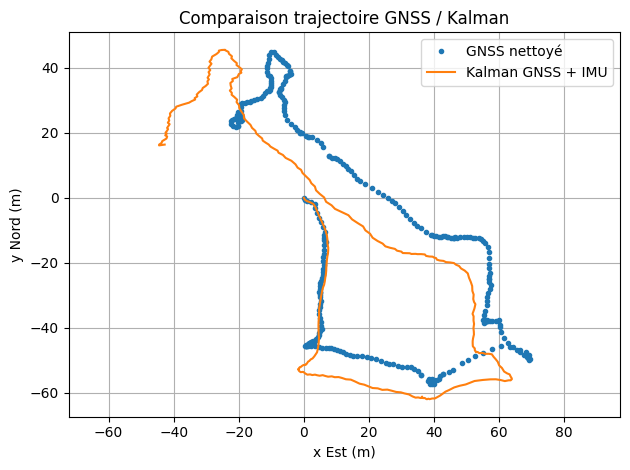

In [238]:
lat0 = clean["latitude"].to_numpy()[0]
lon0 = clean["longitude"].to_numpy()[0]

x_gnss, y_gnss = latlon_to_xy(
    clean["latitude"],
    clean["longitude"],
    lat0,
    lon0
)

x_kalman, y_kalman = latlon_to_xy(
    res["latitude"],
    res["longitude"],
    lat0,
    lon0
)

plt.plot(x_gnss, y_gnss, ".", label="GNSS nettoyé")
plt.plot(x_kalman, y_kalman, "-", label="Kalman GNSS + IMU")

plt.axis("equal")
plt.xlabel("x Est (m)")
plt.ylabel("y Nord (m)")
plt.title("Comparaison trajectoire GNSS / Kalman")
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(out_dir / "comparaison_trajectoire.png", dpi=200)
plt.show()

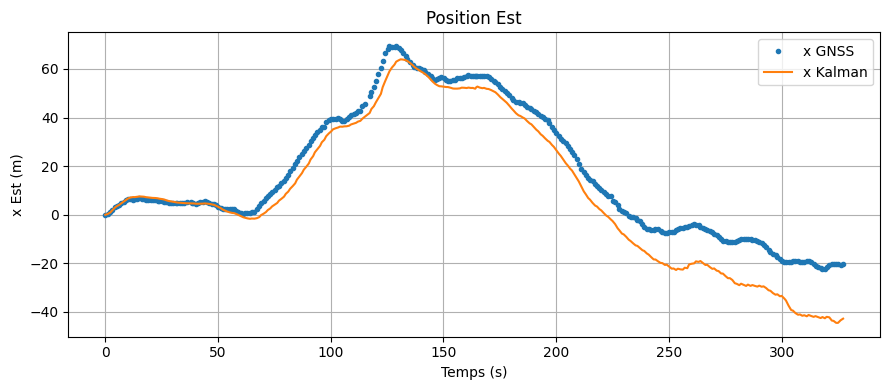

In [239]:
temps = res["timestamp"].to_numpy()

t = temps - temps[0]

plt.figure(figsize=(9, 4))

plt.plot(t, x_gnss, ".", label="x GNSS")
plt.plot(t, x_kalman, "-", label="x Kalman")

plt.xlabel("Temps (s)")
plt.ylabel("x Est (m)")
plt.title("Position Est")
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.show()

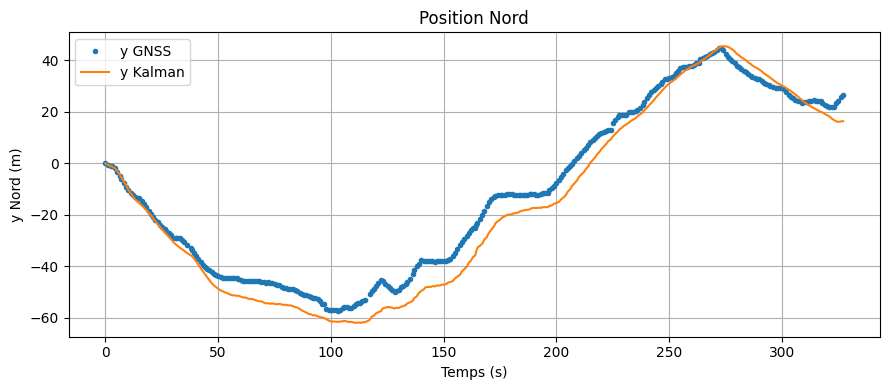

In [240]:
plt.figure(figsize=(9, 4))

plt.plot(t, y_gnss, ".", label="y GNSS")
plt.plot(t, y_kalman, "-", label="y Kalman")

plt.xlabel("Temps (s)")
plt.ylabel("y Nord (m)")
plt.title("Position Nord")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

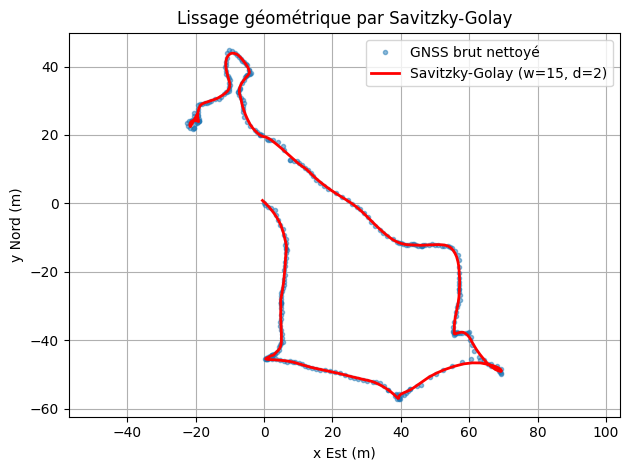

In [230]:
from scipy.signal import savgol_filter

# 1. Extraction des coordonnées locales issues du GPS nettoyé
lat0 = clean["latitude"].to_numpy()[0]
lon0 = clean["longitude"].to_numpy()[0]

x_gnss, y_gnss = latlon_to_xy(clean["latitude"],clean["longitude"],lat0,lon0)

#filtre de Savitzky-Golay
# window_length : Nombre de points de la fenêtre Plus il est grand, plus c'est lisse
# polyorder : Degré du polynôme à ajuster. 2 car il respecte les paraboles pour les virages
window = 15
degre = 2

x_savgol = savgol_filter(x_gnss, window_length=window, polyorder=degre)
y_savgol = savgol_filter(y_gnss, window_length=window, polyorder=degre)

#Reconversion des coordonnées lissées en Latitude / Longitude
lat_savgol, lon_savgol = xy_to_latlon(x_savgol, y_savgol, lat0, lon0)

#sauvegarde
df_savgol = clean.copy()
df_savgol["latitude"] = lat_savgol
df_savgol["longitude"] = lon_savgol
df_savgol.to_csv(out_dir / "savgol_result.csv", index=False)

# Affichage du graphique de comparaison
plt.plot(x_gnss, y_gnss, ".", label="GNSS brut nettoyé", alpha=0.5)
plt.plot(x_savgol, y_savgol, "-", label=f"Savitzky-Golay (w={window}, d={degre})", linewidth=2, color="red")

plt.axis("equal")
plt.xlabel("x Est (m)")
plt.ylabel("y Nord (m)")
plt.title("Lissage géométrique par Savitzky-Golay")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()